In [1]:
# %%
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as spr
from scipy.sparse.linalg import inv
from scipy.interpolate import RegularGridInterpolator, griddata
import cartopy.crs as ccrs
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import matplotlib.ticker as mticker
import matplotlib.colors as colors
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LogNorm, to_rgba
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import matplotlib.dates as mdates


import cmocean
from netCDF4 import Dataset
#from datetime import date, timedelta
import re
import xarray as xr
#from xarray.coders import CFDatetimeCoder

## . . For animation
from matplotlib import animation
from IPython.display import HTML, Image
import geopandas
import rioxarray as rio
from shapely.geometry import mapping, shape
import os
import gc
import pandas as pd
from scipy.interpolate import interp1d
import copy
from pyproj import Transformer
projection = ccrs.SouthPolarStereo()

In [2]:
path = "/Users/rohaizharis/Desktop/Research/Mines/Chapter 1/GRL26"

# %%
IMBIE = geopandas.read_file(path+"/Inputs/ANT_Basins_IMBIE2_v1.6/ANT_Basins_IMBIE2_v1.6.shp", crs="epsg:3031")
scripps = geopandas.read_file(path+"/Inputs/scripps_GL/scripps_antarctica_polygons_v1.shp", crs="epsg:3031")
scripps_gl = scripps.loc[scripps['Id'].astype(int) == 1]
ssb = rio.open_rasterio(path+"/Inputs/AntarcticBasins_BedTypeCode.tif")


/Users/rohaizharis/miniforge3/envs/1d_model/lib/python3.12/site-packages/pyogrio/raw.py:198: RuntimeWarning: driver ESRI Shapefile does not support open option CRS
  return ogr_read(
/Users/rohaizharis/miniforge3/envs/1d_model/lib/python3.12/site-packages/pyogrio/raw.py:198: RuntimeWarning: driver ESRI Shapefile does not support open option CRS
  return ogr_read(


In [3]:
qs = ['A1','A2','A3','A4']
ds_smb = {q: xr.open_dataset(f'{path}/Inputs/ICESat2/gsfc_ATL15_{q}_0329_10km_005_02.nc') for q in qs}
SMB = (ds_smb['A1']
         .combine_first(ds_smb['A2'])
         .combine_first(ds_smb['A3'])
         .combine_first(ds_smb['A4']))

nt,ny,nx = np.shape(SMB.zsurf)
nt = 22
smb_lag1 = np.zeros((nt,ny,nx),dtype=float)
for i in range(0,nt):
    #difference of adjacent surfaces divided by 0.25, a quarter of the year
    dsmb_dt = (SMB.zsurf[i+1,:,:] - SMB.zsurf[i,:,:])/0.25
    smb_lag1[i,:,:] = dsmb_dt

ds_atl = {q: xr.open_dataset(f'{path}/Inputs/ICESat2/ATL15_{q}_0329_10km_005_02.nc',
                         group='dhdt_lag1') for q in qs}

ATL15 = (ds_atl['A1']
         .combine_first(ds_atl['A2'])
         .combine_first(ds_atl['A3'])
         .combine_first(ds_atl['A4']))


for i in range(0,nt):
    ATL15.dhdt[i,:,:] = ATL15.dhdt[i,:,:] - smb_lag1[i,:,:]


In [4]:
atl15_x, atl15_y = np.meshgrid(ATL15.x.values, ATL15.y.values)
ssb = ssb.rio.clip(scripps_gl.geometry.apply(mapping), scripps_gl.crs)

ssb_x, ssb_y = np.meshgrid(ssb.x, ssb.y)
ssb_val = ssb.values
ssb_val = ssb_val[0,:,:]
ssb_val[ssb_val < -9000] = np.nan

interp = RegularGridInterpolator(points=[ssb.x.values,ssb.y.values], values=ssb_val.T, method="nearest", fill_value=np.nan, bounds_error = False)
ssb_new = interp((atl15_x, atl15_y))

perm_var = np.zeros_like(ssb_new)
perm_var[ssb_new == 3] = 1e-13      #T1 Basin
perm_var[ssb_new == 2] = 1e-13      #T2 Basin
perm_var[ssb_new == 1] = 1e-13          #Intrabasin volcanics 
perm_var[ssb_new == 0] = 1e-21      #Crystalline
perm_var[ssb_new == -1] = 1e-17     #T2 + C
perm_var[ssb_new == -2] = 1e-18     #T1 and C
perm_var[ssb_new == -3] = 1e-13     #T1 and T2

ATL15["perm_var"] = (['y', 'x'], perm_var)
ATL15.rio.write_crs("epsg:3031", inplace=True)

<xarray.Dataset> Size: 83MB
Dimensions:              (time: 28, y: 446, x: 546)
Coordinates:
  * time                 (time) datetime64[ns] 224B 2019-02-15T21:45:00 ... 2...
  * y                    (y) float64 4kB -2.185e+06 -2.175e+06 ... 2.265e+06
  * x                    (x) float64 4kB -2.665e+06 -2.655e+06 ... 2.785e+06
    Polar_Stereographic  int64 8B 0
Data variables:
    ice_area             (time, y, x) float32 27MB nan nan nan ... nan nan nan
    dhdt                 (time, y, x) float32 27MB nan nan nan ... nan nan nan
    dhdt_sigma           (time, y, x) float32 27MB nan nan nan ... nan nan nan
    perm_var             (y, x) float32 974kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
Attributes:
    description:  dhdt_lag1 group includes variables describing height differ...

In [5]:
thk = xr.open_dataset(path+"/Inputs/Ant_Crust.nc")
thk.rio.write_crs("epsg:3031", inplace=True)
thk = thk.rio.clip(scripps_gl.geometry.apply(mapping), scripps_gl.crs)
thk_val = np.array(thk["Mean_SSB_th"].values)
thk_val[np.isnan(thk_val)] = 0
thk_x, thk_y = np.meshgrid(thk.x, thk.y)
interp = RegularGridInterpolator(points=[thk.x.values,thk.y.values], values=thk_val.T, method="linear", fill_value=np.nan, bounds_error = False)
thk_new = interp((atl15_x, atl15_y))

dz = 100
thk_threshold = copy.deepcopy(thk_new)
thk_threshold[thk_threshold < 300] = np.nan
thk_discr = np.round(thk_threshold / dz) * dz
max_L = thk_discr[~np.isnan(thk_discr)].max()
max_nz = int(max_L/dz) + 2

ATL15["thk_discr"] = (['y', 'x'], thk_discr)
ATL15.rio.write_crs("epsg:3031", inplace=True)

<xarray.Dataset> Size: 85MB
Dimensions:              (time: 28, y: 446, x: 546)
Coordinates:
  * time                 (time) datetime64[ns] 224B 2019-02-15T21:45:00 ... 2...
  * y                    (y) float64 4kB -2.185e+06 -2.175e+06 ... 2.265e+06
  * x                    (x) float64 4kB -2.665e+06 -2.655e+06 ... 2.785e+06
    Polar_Stereographic  int64 8B 0
Data variables:
    ice_area             (time, y, x) float32 27MB nan nan nan ... nan nan nan
    dhdt                 (time, y, x) float32 27MB nan nan nan ... nan nan nan
    dhdt_sigma           (time, y, x) float32 27MB nan nan nan ... nan nan nan
    perm_var             (y, x) float32 974kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    thk_discr            (y, x) float64 2MB nan nan nan nan ... nan nan nan nan
Attributes:
    description:  dhdt_lag1 group includes variables describing height differ...

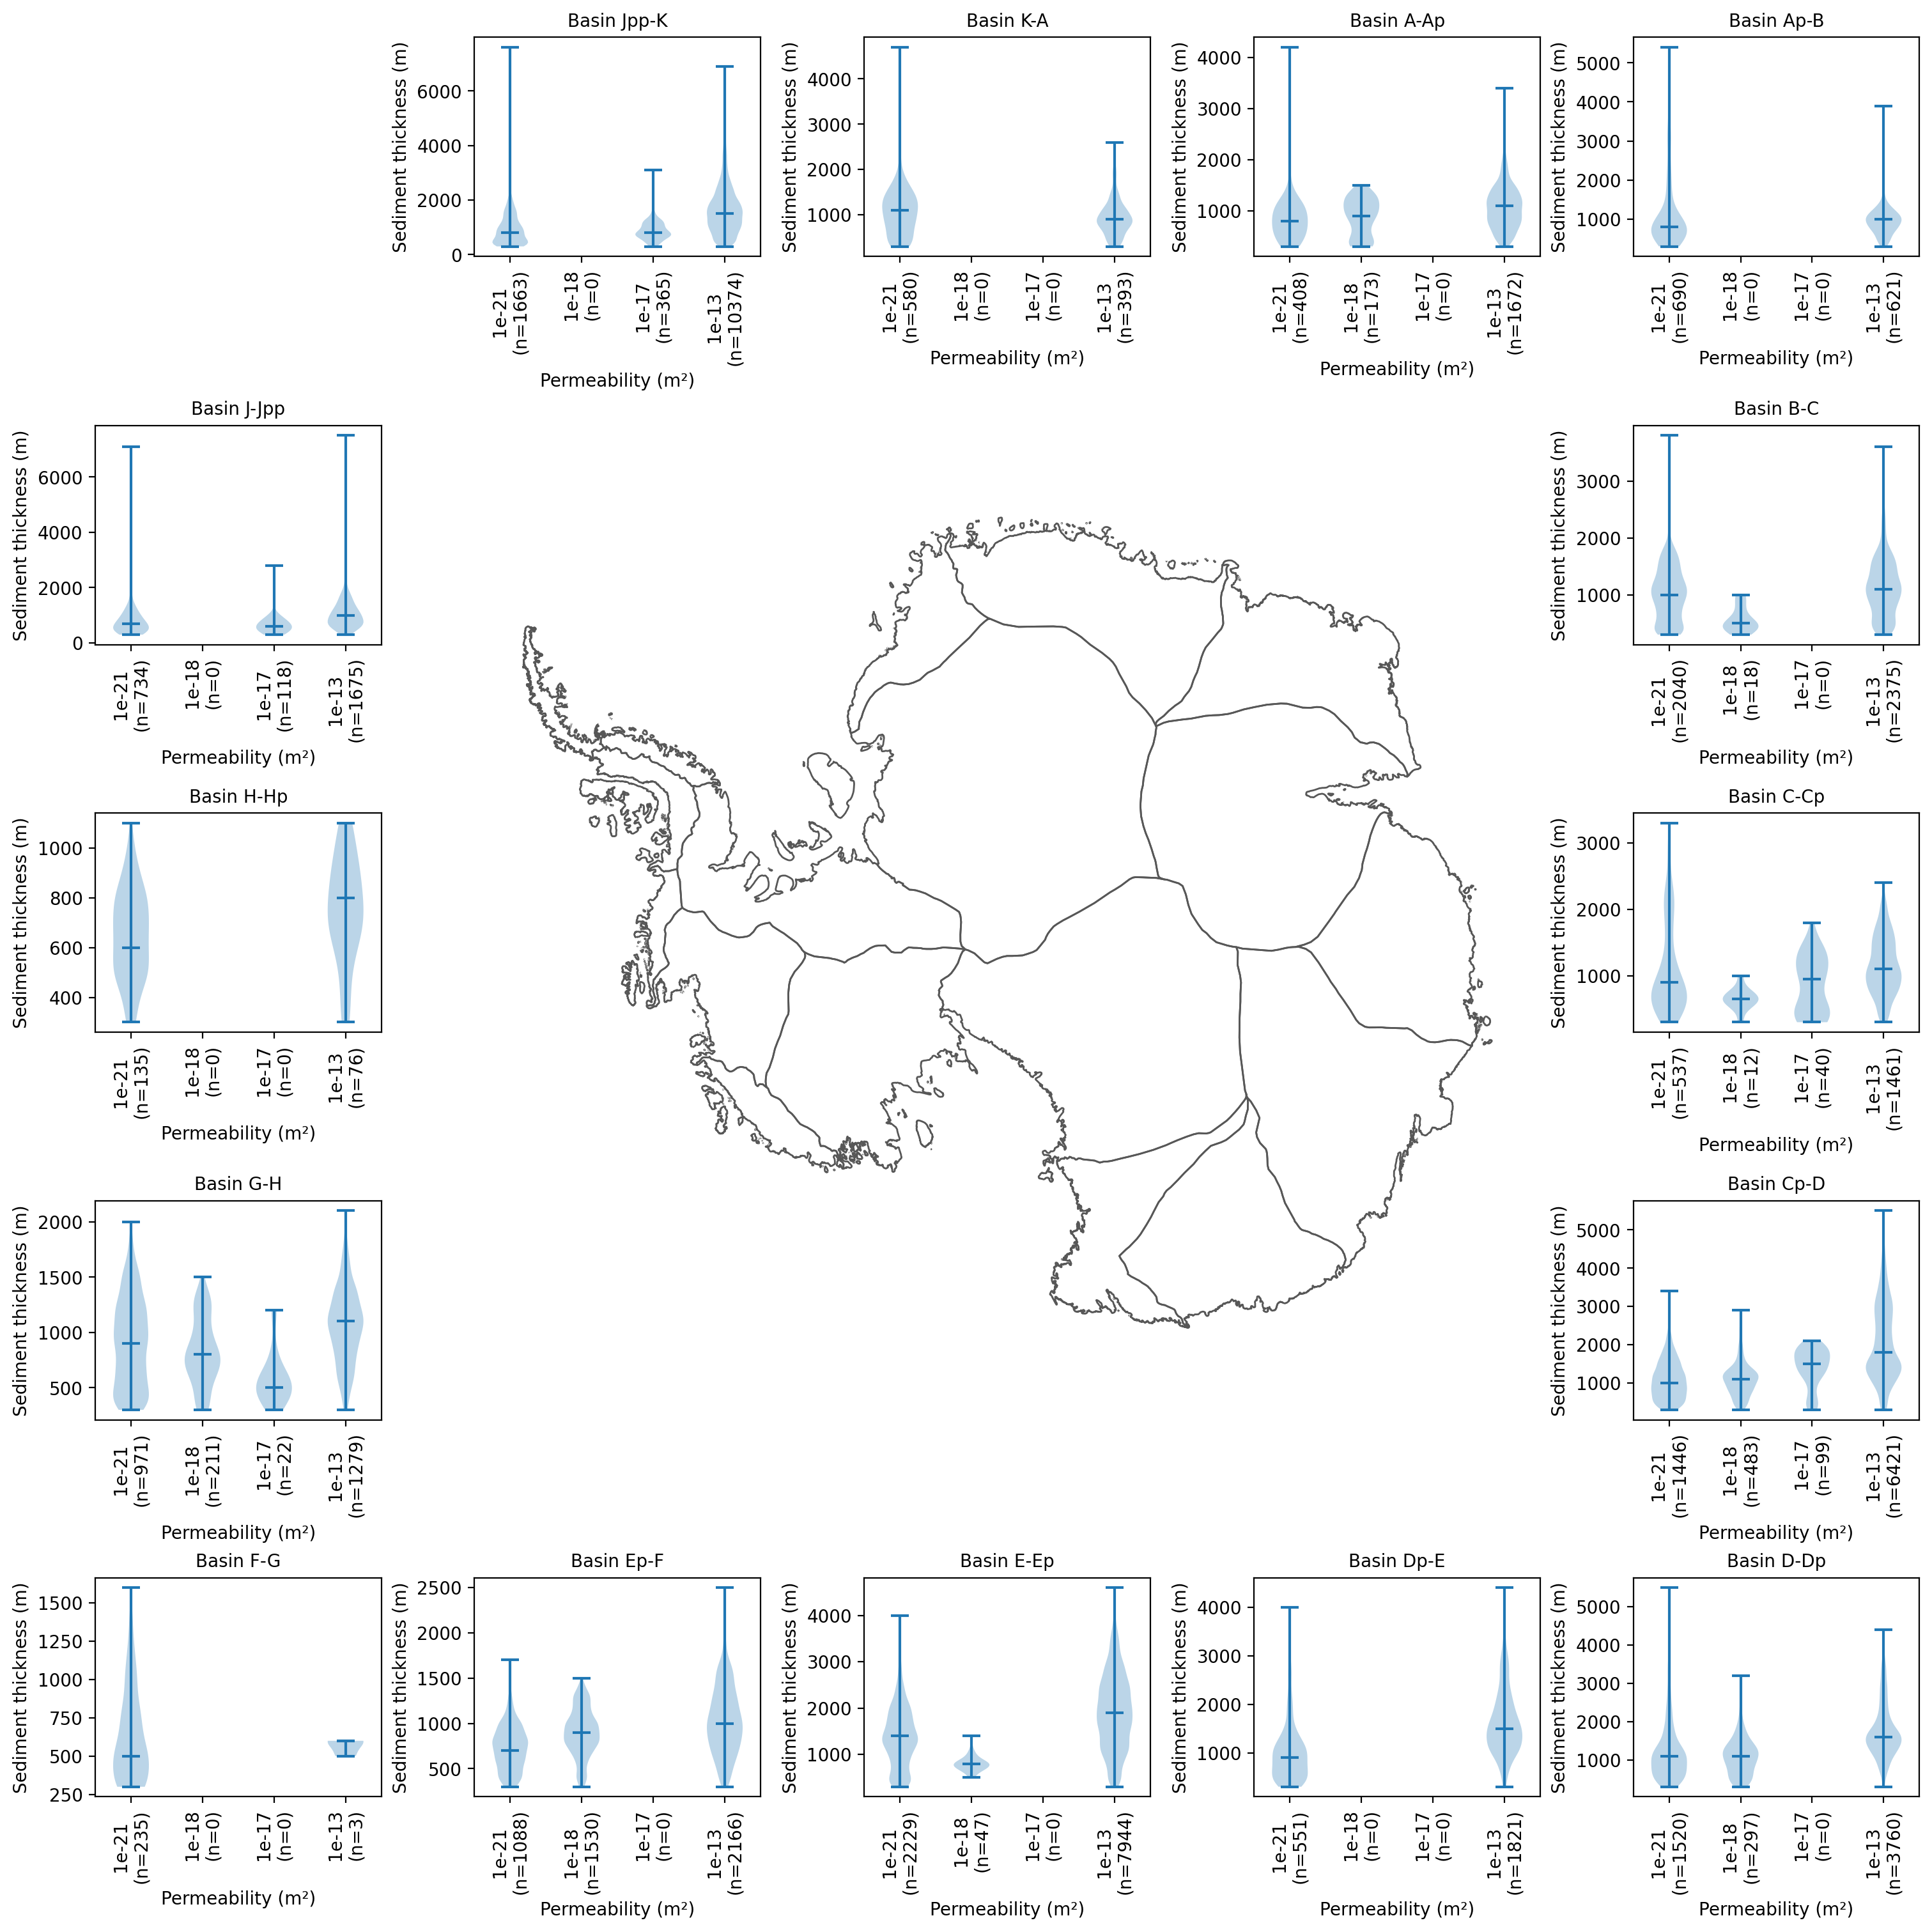

In [7]:
def plot_sed(ax, bas):
    ATL15_clip = ATL15.rio.clip(
        [IMBIE.loc[bas].geometry],
        IMBIE.crs,
        drop=True
    )
    perm_flat = np.asarray(ATL15_clip["perm_var"].values).ravel()
    thk_flat = np.asarray(ATL15_clip["thk_discr"].values).ravel()
    mask = np.isfinite(perm_flat) & np.isfinite(thk_flat) & (perm_flat > 0)
    perm_clean = perm_flat[mask]
    thk_clean = thk_flat[mask]

    perm_classes = [1e-21, 1e-18, 1e-17, 1e-13]
    thk_by_class = [thk_clean[perm_clean == p] for p in perm_classes]

    positions = [i + 1 for i, t in enumerate(thk_by_class) if len(t) > 0]
    non_empty = [t for t in thk_by_class if len(t) > 0]

    if non_empty:
        parts = ax.violinplot(non_empty, positions=positions, showmedians=True)

    ax.set_xticks(range(1, 5))
    ax.set_xticklabels([f'{p:.0e}\n(n={len(t)})'
                        for p, t in zip(perm_classes, thk_by_class)])
    ax.set_xlim(0.5, 4.5)
    plt.xticks(rotation="vertical")
    ax.set_xlabel('Permeability (m²)')
    ax.set_ylabel('Sediment thickness (m)')
    plt.title('Basin '+ IMBIE.loc[bas].Subregion, fontsize = 10)




fig = plt.figure(figsize=(15,15), dpi=200,constrained_layout=True)
spec = gridspec.GridSpec(ncols=5, nrows=5, figure=fig)
ax_AA = fig.add_subplot(spec[1:-1,1:-1])
IMBIE.plot(ax=ax_AA, color="none", edgecolor='#575757',facecolor="none",linewidth=1)
plt.axis('off')
time = np.arange(np.datetime64("2019-01-01"), np.datetime64("2300-01-05"), np.timedelta64(65,'D'))

ax_jppk = fig.add_subplot(spec[0,1])
plot_sed(ax_jppk,8)

ax_ka = fig.add_subplot(spec[0,2])
plot_sed(ax_ka,13)

ax_aap = fig.add_subplot(spec[0,3])
plot_sed(ax_aap,7)

ax_apb = fig.add_subplot(spec[0,4])
plot_sed(ax_apb,11)

ax_bc = fig.add_subplot(spec[1,4])
plot_sed(ax_bc,6)

ax_ccp = fig.add_subplot(spec[2,4])
plot_sed(ax_ccp,12)

ax_cpd = fig.add_subplot(spec[3,4])
plot_sed(ax_cpd,5)

ax_ddp = fig.add_subplot(spec[4,4])
plot_sed(ax_ddp,4)

ax_dpe = fig.add_subplot(spec[4,3])
plot_sed(ax_dpe,10)

ax_eep = fig.add_subplot(spec[4,2])
plot_sed(ax_eep,3)

ax_epf = fig.add_subplot(spec[4,1])
plot_sed(ax_epf,18)

ax_fg = fig.add_subplot(spec[4,0])
plot_sed(ax_fg,2)

ax_gh = fig.add_subplot(spec[3,0])
plot_sed(ax_gh,9)

ax_hhp = fig.add_subplot(spec[2,0])
plot_sed(ax_hhp,1)

ax_jjpp = fig.add_subplot(spec[1,0])
plot_sed(ax_jjpp,14)
plt.savefig("thkperm.png")